# <center>🌸 Практика 3. Классификация ирисов (Iris)</center>
### <center>Прикладные технологии ИИ · 120 минут (2 ч.) · Модуль 2</center>

<div style='text-align: center; margin: 20px;'>
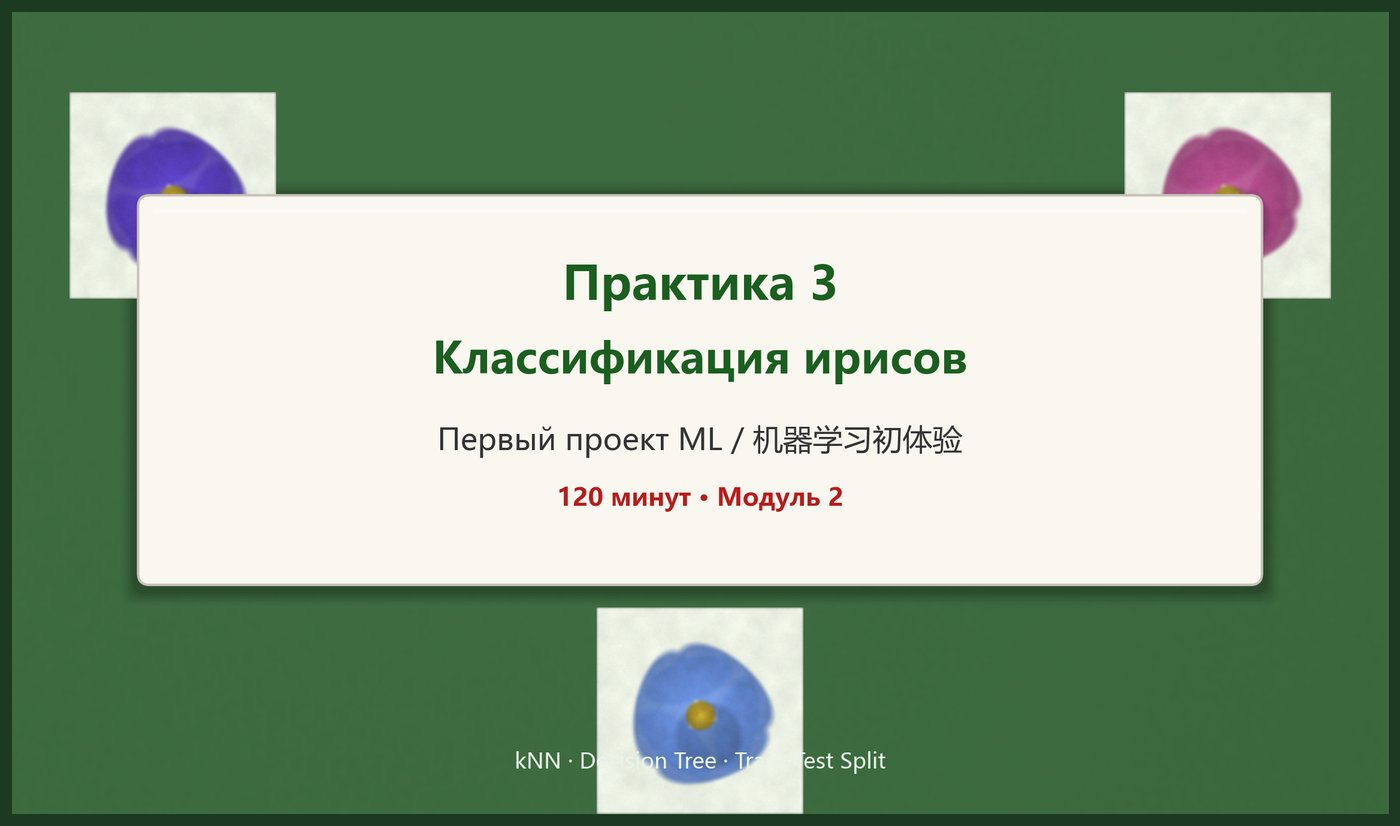
</div>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цель практики:</b><br>
Пройти полный путь «данные → обучение → проверка → прогноз» на классическом наборе данных. Сравнить три алгоритма: LogisticRegression, kNN и Решающее дерево.<br><br>
<b>⏱️ План работы (120 мин):</b><br>
• 15 мин — Повторение идеи и разбор кода<br>
• 20 мин — Знакомство с данными и график<br>
• 30 мин — Запуск двух моделей (kNN и Дерево)<br>
• 25 мин — Эксперименты с параметрами (таблица точности)<br>
• 15 мин — Очистка «грязных» данных<br>
• 15 мин — Прогноз для нового цветка и выводы
</div>

<center><i>Преподаватель: _______________</i></center>
<center><i>Дата: _______________</i></center>
<center><i>Студент: _______________</i></center>

---
## 📖 Введение: что такое классификация

**Классификация** — это один из двух главных типов задач обучения с учителем (второй — регрессия). В отличие от регрессии, где модель предсказывает *число* (цену дома, температуру завтра), в классификации модель предсказывает **категорию** — дискретную метку класса. Например: это письмо — спам или нет? Эта опухоль — злокачественная или доброкачественная? Этот цветок — ирис сорта *setosa*, *versicolor* или *virginica*?

**Почему именно Iris?** Набор данных Iris собрал ещё в 1936 году биолог Рональд Фишер. В нём всего 150 наблюдений (по 50 на каждый из трёх видов) и 4 признака: длина и ширина чашелистика (sepal) и лепестка (petal). Iris стал «Hello, World!» машинного обучения: данные маленькие, чистые, легко визуализируются, но при этом содержат нелинейную разделимость (versicolor и virginica пересекаются), что позволяет увидеть разницу между алгоритмами. Ни один курс по ML не обходится без Iris — и мы не исключение.

**Какие алгоритмы будем сравнивать.** В этой практике мы возьмём три классических модели из библиотеки scikit-learn:

1. **Логистическая регрессия (LogisticRegression)** — линейный классификатор, быстрая и интерпретируемая.
2. **k-ближайших соседей (KNeighborsClassifier)** — «ленивый» алгоритм: запоминает обучающие данные и голосует за класс соседей.
3. **Решающее дерево (DecisionTreeClassifier)** — древовидная структура правил вида «если длина лепестка < 2.45, то setosa».

Мы пройдём весь конвейер: загрузка данных → разделение на train/test → обучение трёх моделей → сравнение точности → матрица ошибок → прогноз для нового цветка. Это базовый «пайплайн» классификации, который вы будете переиспользовать во всех будущих проектах.

<div style='background-color: #E3F2FD; padding: 12px; border-left: 5px solid #1976D2; margin: 15px 0;'>
<b>💡 Главный принцип классификации:</b> модель учится находить <i>границу решения</i> (decision boundary) в пространстве признаков — такую, что по одну сторону лежат в основном объекты одного класса, по другую — другого. Разные алгоритмы строят эту границу по-разному: прямая линия у логистической регрессии, «ступеньки» у дерева, сложная кусочная поверхность у kNN.
</div>


---
## 🔧 1. Настройка среды и импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Библиотеки Scikit-learn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Настройка шрифтов для графиков
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

print('✅ Все библиотеки успешно импортированы')

✅ Все библиотеки успешно импортированы


---
## 📊 2. Знакомство с данными Iris

<div style='text-align: center; margin: 20px;'>
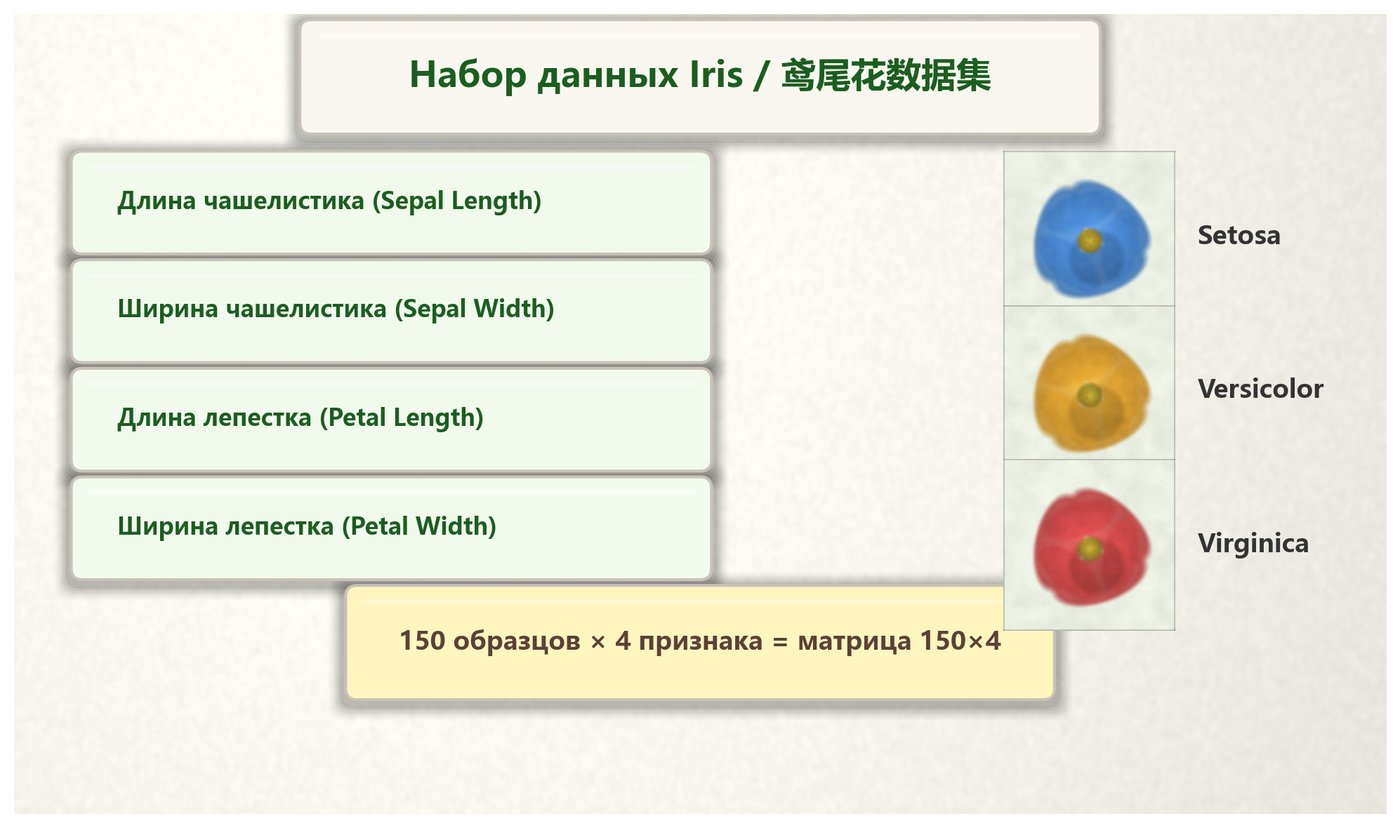
</div>

Набор данных встроен в `scikit-learn`, интернет не нужен. Это 150 образцов трех видов ирисов.

In [2]:
# Загружаем данные как DataFrame (таблицу)
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

print('Размер данных:', X.shape)
print('\nПервые 5 строк:')
X.head()

Размер данных: (150, 4)

Первые 5 строк:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
print('Названия классов:', iris.target_names)
print('\nСтатистика по признакам:')
X.describe()

Названия классов: ['setosa' 'versicolor' 'virginica']

Статистика по признакам:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### Визуализация
Посмотрим, как распределяются длина и ширина лепестков для разных видов.

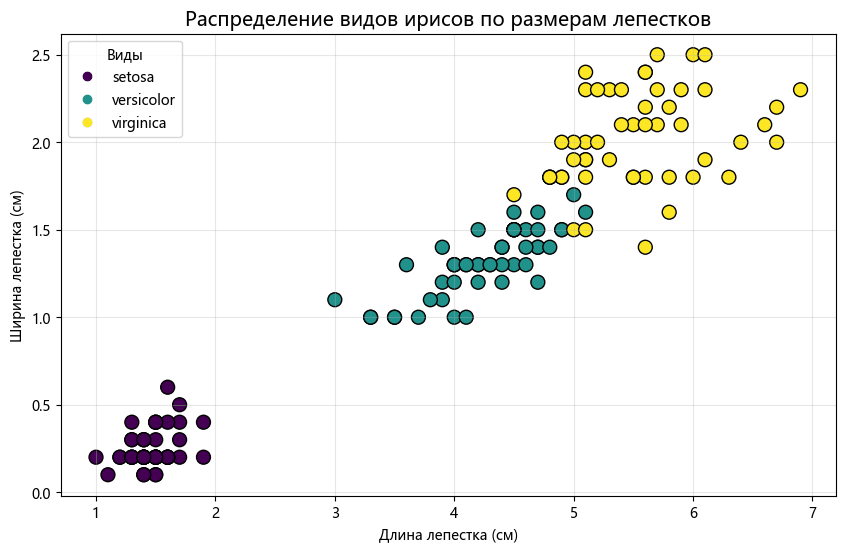

In [4]:
# График: длина и ширина лепестка, цвет = вид цветка
plt.figure(figsize=(10, 6))
scatter = plt.scatter(X['petal length (cm)'], X['petal width (cm)'], c=y, cmap='viridis', s=100, edgecolors='black')
plt.title('Распределение видов ирисов по размерам лепестков', fontsize=14)
plt.xlabel('Длина лепестка (см)')
plt.ylabel('Ширина лепестка (см)')

# ИСПРАВЛЕННАЯ легенда
handles, labels = scatter.legend_elements()
plt.legend(handles, iris.target_names, title="Виды")

plt.grid(True, alpha=0.3)
plt.show()

---
## 🛠️ 3. Разделение данных и обучение моделей

<div style='text-align: center; margin: 20px;'>
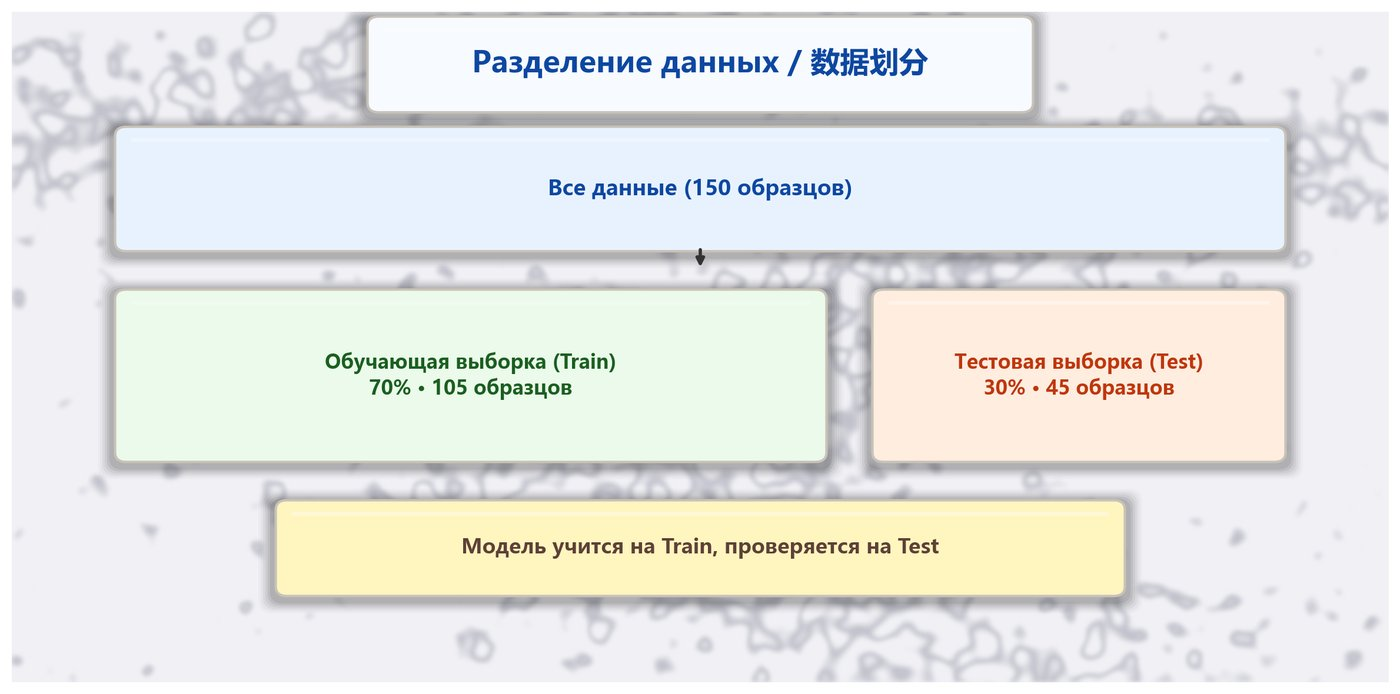
</div>

Мы разделим данные на **обучающую** (70%) и **тестовую** (30%) выборки. Тестовая выборка нужна, чтобы честно проверить модель на данных, которые она раньше не видела.

### 🧩 Почему данные обязательно разделять?

Функция `train_test_split(X, y, test_size=0.3, random_state=42)` из `sklearn.model_selection` делает ровно то, что следует из её названия: **перемешивает** все 150 строк и **раскладывает** их в две «кучки» — обучающую (70 %, 105 образцов) и тестовую (30 %, 45 образцов). Параметр `random_state=42` фиксирует «зерно» генератора случайных чисел, поэтому при каждом запуске разбиение получается одинаковым — это нужно для воспроизводимости экспериментов.

**Зачем это нужно?** Если обучать и проверять модель на одних и тех же данных, она может просто **запомнить** (заучить) все примеры вместе с их метками — как школьник, вызубривший ответы на контрольную. На новых данных такая модель провалится. Это явление называется **переобучением (overfitting)**: модель идеально работает на «своих» данных и плохо — на «чужих». Тестовая выборка имитирует «чужие» данные: модель её не видит во время обучения, и точность на ней (`accuracy_score(y_test, pred)`) — честная оценка того, как модель поведёт себя в реальной работе.

**Правило большого пальца:** 70/30 или 80/20 — стандартные пропорции. Для маленьких данных (как Iris) часто используют **k-fold кросс-валидацию**: делят данные на k частей и k раз обучают модель, оставляя одну часть на тест. Но для этой практики простого 70/30 разбиения достаточно.

<div style='background-color: #FFF8E1; padding: 12px; border-left: 5px solid #F57F17; margin: 15px 0;'>
<b>⚠️ Типичная ошибка новичка:</b> смотреть на <code>model.score(X_train, y_train)</code> и радоваться «0.99 точности!».<br>
Это <i>обучающая</i> точность — она почти всегда высокая и почти всегда бесполезна. Смотреть надо только на <b>тестовую</b> точность: <code>accuracy_score(y_test, model.predict(X_test))</code>.
</div>


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f'Обучающая выборка: {X_train.shape[0]} образцов')
print(f'Тестовая выборка: {X_test.shape[0]} образцов')

Обучающая выборка: 105 образцов
Тестовая выборка: 45 образцов


---
### 🔍 Краткий обзор трёх алгоритмов

Перед тем как запускать код, давайте за 30 секунд вспомним, как устроена каждая модель. Это поможет объяснить разницу в результатах.

**1. Логистическая регрессия (`LogisticRegression`).** Вопреки названию, это **классификатор**, а не регрессия. Модель строит **линейную границу** между классами — гиперплоскость вида $w_1 x_1 + w_2 x_2 + \dots + b = 0$ — и переводит расстояние до неё в вероятность через сигмоиду. Очень быстрая, обучается за миллисекунды, хорошо интерпретируется (коэффициенты $w_i$ показывают «вес» каждого признака). Платит за это тем, что может разделить только **линейно разделимые** классы — versicolor и virginica у ирисов частично перекрываются, поэтому логистическая регрессия иногда ошибается.

**2. k-ближайших соседей (`KNeighborsClassifier`, kNN).** «Ленивый» алгоритм — он ничего не обучает заранее, а просто **запоминает** обучающие точки. Когда приходит новый объект, kNN находит k ближайших к нему соседей из обучающей выборки и голосованием определяет класс. Главное преимущество — **простота и отсутствие обучения**; главное требование — **масштабированные признаки** (иначе признак с большими числами «задавит» маленькие). Параметр `k` (у нас 5) — баланс смещения/дисперсии: маленькое k даёт сложную границу (риск переобучения), большое k — простую, но «огрублённую».

**3. Решающее дерево (`DecisionTreeClassifier`).** Строит бинарное дерево правил вида «если `petal length ≤ 2.45`, то setosa». На каждом шаге алгоритм выбирает признак и порог, лучше всего разделяющие классы (по критерию Джини или энтропии). Дерево **интерпретируемо человеком** (можно нарисовать и прочитать), **не зависит от масштаба** признаков и **ловит нелинейные зависимости**. Главный риск — легко переобучается, вырастая в «густой куст» с одним листом на каждый пример. Поэтому ограничивают глубину (`max_depth=3`) или используют ансамбли (Random Forest, Gradient Boosting).

<div style='background-color: #F3E5F5; padding: 12px; border-left: 5px solid #7B1FA2; margin: 15px 0;'>
<b>🆚 Краткое сравнение</b><br>
<table>
<tr><th>Свойство</th><th>LogReg</th><th>kNN</th><th>Дерево</th></tr>
<tr><td>Тип границы</td><td>линейная</td><td>кусочная</td><td>«ступеньки»</td></tr>
<tr><td>Обучение</td><td>быстрое</td><td>отсутствует</td><td>среднее</td></tr>
<tr><td>Чувствительность к масштабу</td><td>да</td><td><b>очень</b></td><td>нет</td></tr>
<tr><td>Интерпретируемость</td><td>коэффициенты</td><td>низкая</td><td>дерево правил</td></tr>
</table>
</div>


### Сравнение трёх алгоритмов

<div style='text-align: center; margin: 20px;'>
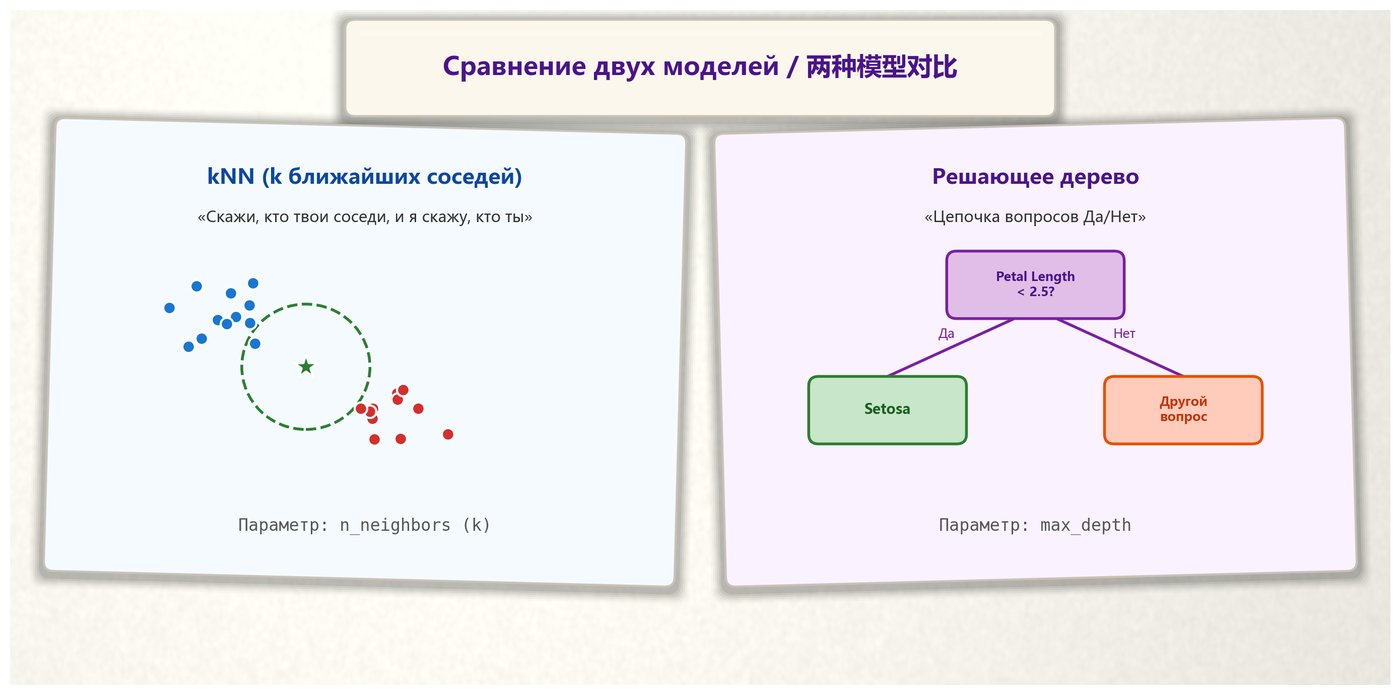
</div>

In [6]:
# Создаем словарь моделей
models = {
    'LogReg': LogisticRegression(max_iter=200),
    'kNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Дерево (depth=3)': DecisionTreeClassifier(max_depth=3, random_state=42)
}

# Обучаем и оцениваем каждую модель
for name, model in models.items():
    print(f"\n--- Модель: {name} ---")
    
    # 1. Обучение (fit)
    model.fit(X_train, y_train)
    
    # 2. Прогноз (predict)
    pred = model.predict(X_test)
    
    # 3. Оценка (evaluate)
    acc = accuracy_score(y_test, pred)
    print(f'Точность (Accuracy): {acc:.2f}')
    
    print('Матрица ошибок:')
    print(confusion_matrix(y_test, pred))
    
    print('Отчет классификации:')
    print(classification_report(y_test, pred, target_names=iris.target_names))


--- Модель: kNN (k=5) ---
Точность (Accuracy): 1.00
Матрица ошибок:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Отчет классификации:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45


--- Модель: Дерево (depth=3) ---
Точность (Accuracy): 1.00
Матрица ошибок:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Отчет классификации:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.0

### Как работает решающее дерево?

<div style='text-align: center; margin: 20px;'>
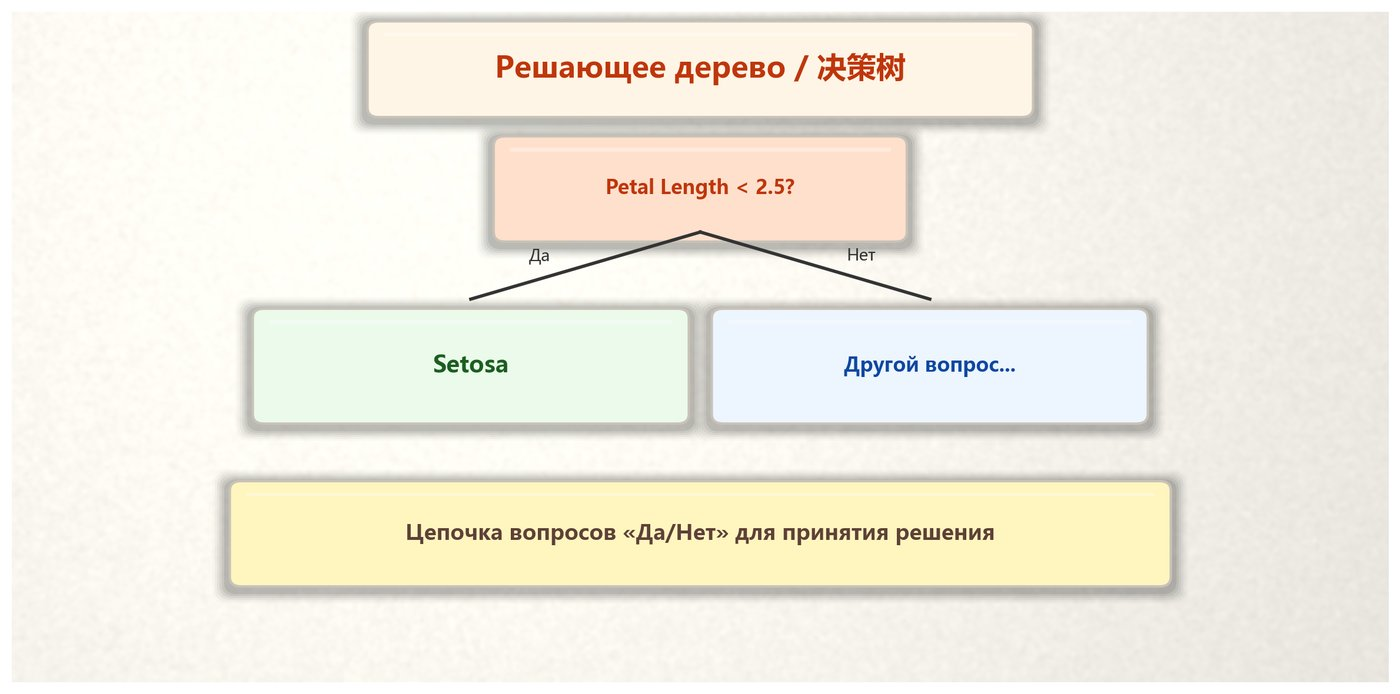
</div>

---
## 🧪 4. Эксперименты с параметрами (Задание 1)

<div style='text-align: center; margin: 20px;'>
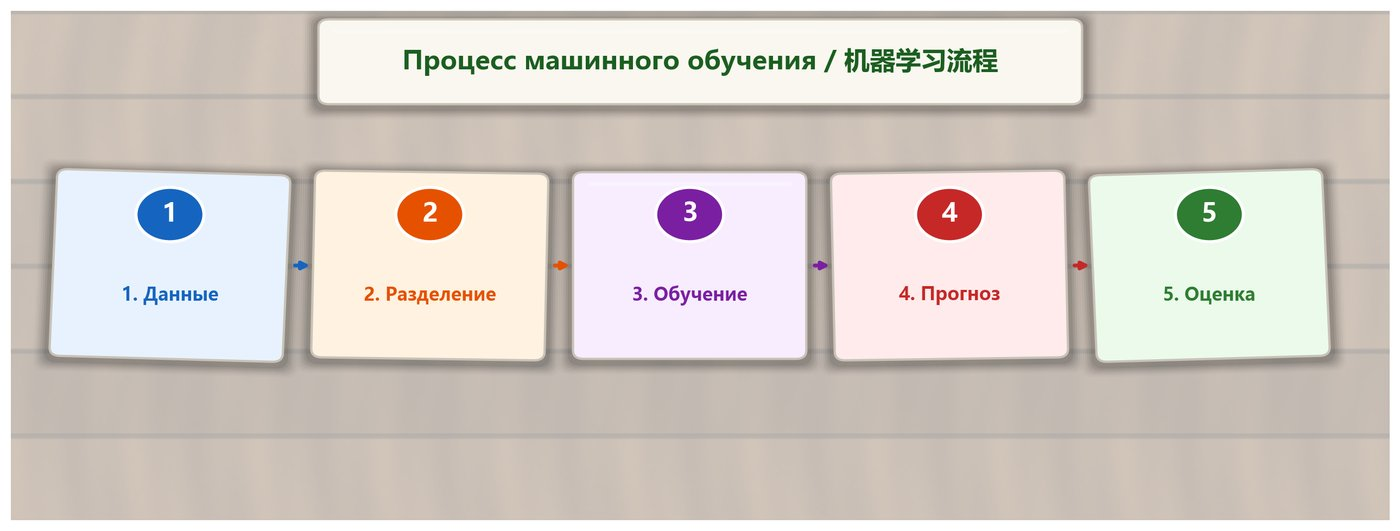
</div>

Заполните таблицу, меняя параметры моделей. Как меняется точность? Какое значение лучше?

| Параметр kNN (n_neighbors) | Точность kNN | Параметр Дерева (max_depth) | Точность Дерева |
|----------------------------|--------------|-----------------------------|-----------------|
| 1                          |              | 1                           |                 |
| 3                          |              | 2                           |                 |
| 5                          |              | 3                           |                 |
| 15                         |              | 5                           |                 |

In [7]:
# Код для автоматического заполнения таблицы

k_values = [1, 3, 5, 15]
depth_values = [1, 2, 3, 5]

print("Эксперименты с kNN:")
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test))
    print(f"k={k} -> Accuracy: {acc:.2f}")

print("\nЭксперименты с Деревом:")
for d in depth_values:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree.fit(X_train, y_train)
    acc = accuracy_score(y_test, tree.predict(X_test))
    print(f"depth={d} -> Accuracy: {acc:.2f}")

Эксперименты с kNN:
k=1 -> Accuracy: 1.00
k=3 -> Accuracy: 1.00
k=5 -> Accuracy: 1.00
k=15 -> Accuracy: 1.00

Эксперименты с Деревом:
depth=1 -> Accuracy: 0.71
depth=2 -> Accuracy: 0.98
depth=3 -> Accuracy: 1.00
depth=5 -> Accuracy: 1.00


---
## 🧹 5. Очистка «грязных» данных (Задание 2)

В реальных данных часто бывают пропуски. Давайте искусственно испортим данные, заполним пропуски средним и посмотрим, упадет ли точность.

In [8]:
# 1. Делаем «грязную» копию
X_dirty = X.copy()

# 2. Вставляем пропуски (None) в каждый 20-й элемент первого столбца
X_dirty.iloc[::20, 0] = None

print('Количество пропусков до очистки:', X_dirty.isnull().sum().sum())

# 3. Заполняем пропуски средним значением столбца
X_dirty = X_dirty.fillna(X_dirty.mean())

print('Количество пропусков после очистки:', X_dirty.isnull().sum().sum())

# 4. Заново разделяем и обучаем модель kNN
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(X_dirty, y, test_size=0.3, random_state=42)

knn_dirty = KNeighborsClassifier(n_neighbors=5)
knn_dirty.fit(X_train_d, y_train_d)
pred_dirty = knn_dirty.predict(X_test_d)

acc_dirty = accuracy_score(y_test_d, pred_dirty)
print(f'\nТочность на "грязных" данных: {acc_dirty:.2f}')

Количество пропусков до очистки: 8
Количество пропусков после очистки: 0

Точность на "грязных" данных: 1.00


---
## 🔮 6. Прогноз для нового цветка (Задание 3)

Придумайте свои четыре числа (параметры цветка) и проверьте, какой вид предскажет модель.

In [9]:
# Пример: цветок с маленькими лепестками
my_flower = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=X.columns)

# Используем последнюю обученную модель (kNN)
prediction = knn_dirty.predict(my_flower)
predicted_name = iris.target_names[prediction[0]]

print(f'Для цветка {my_flower.values[0]} модель предсказала вид: {predicted_name}')

Для цветка [5.1 3.5 1.4 0.2] модель предсказала вид: setosa


---
## 📊 Матрица ошибок

<div style='text-align: center; margin: 20px;'>
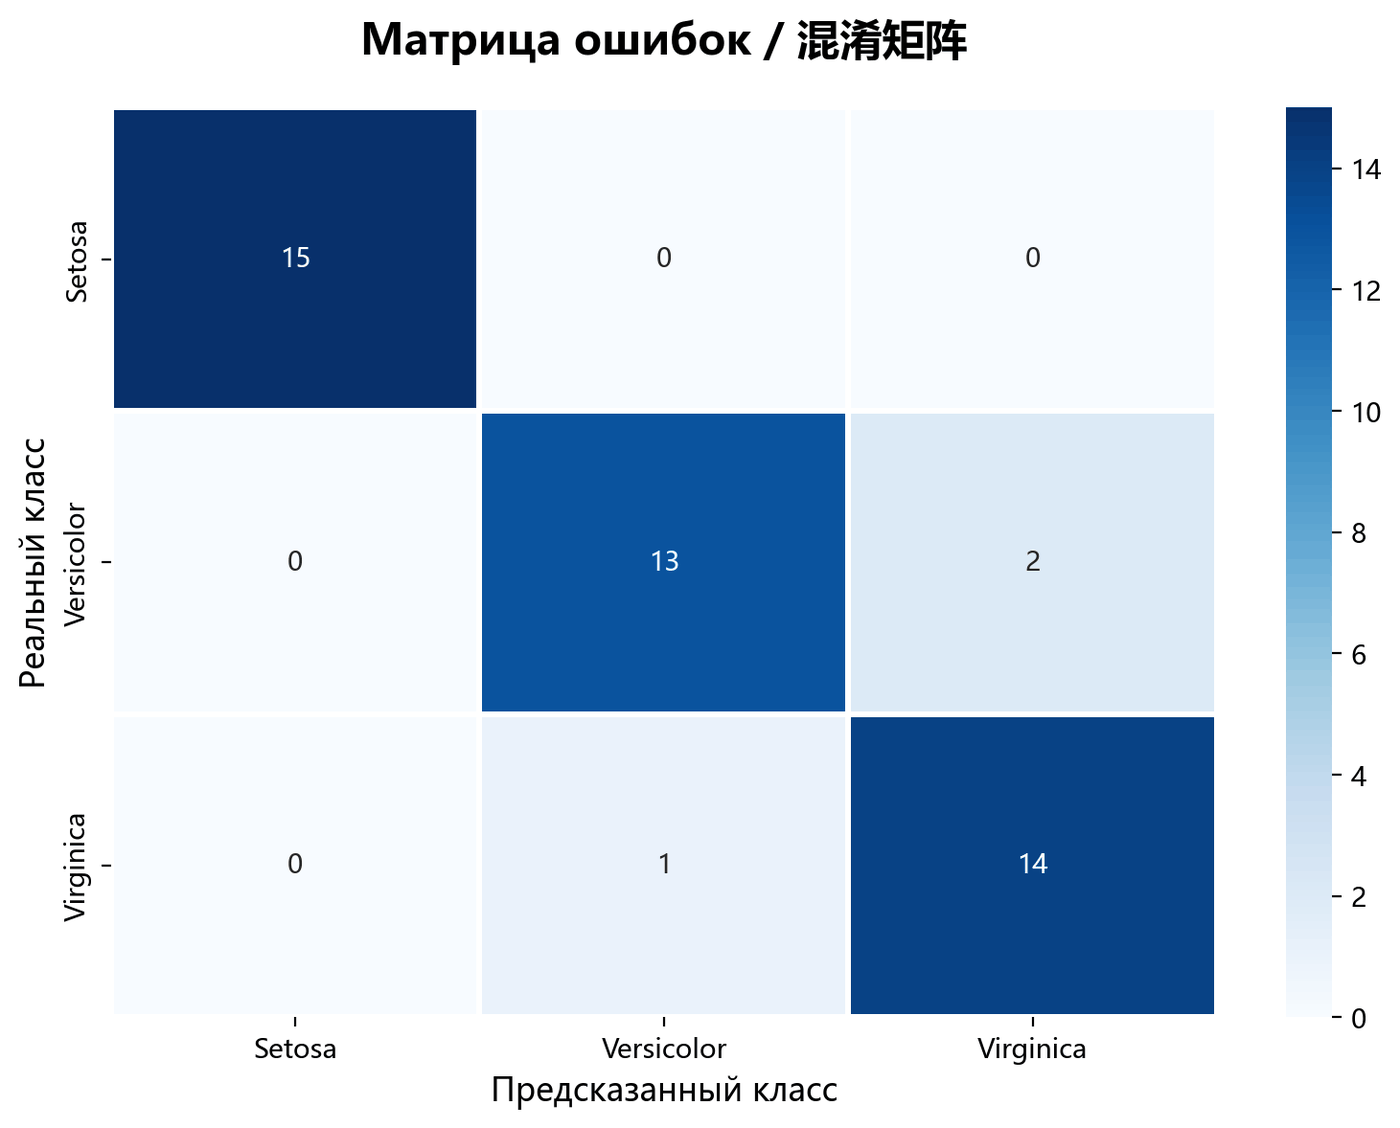
</div>

Матрица ошибок показывает, где именно модель ошиблась. По диагонали — правильные ответы.

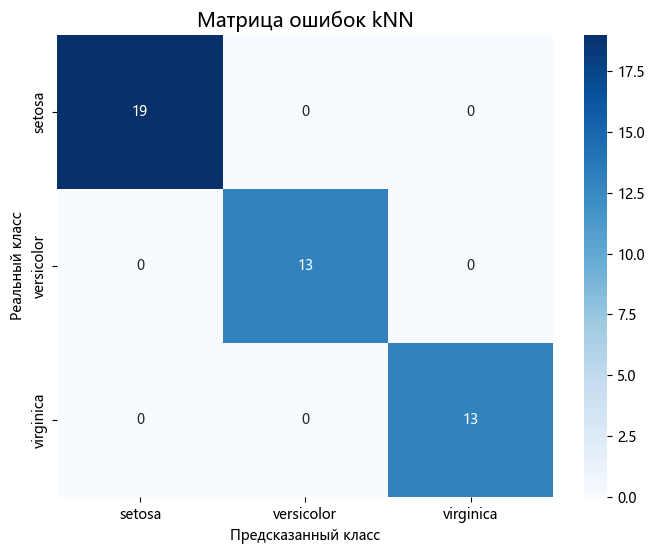

In [10]:
# Строим матрицу ошибок для kNN
cm = confusion_matrix(y_test, knn.predict(X_test))

plt.figure(figsize=(8, 6))
import seaborn as sns
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.title('Матрица ошибок kNN', fontsize=14)
plt.ylabel('Реальный класс')
plt.xlabel('Предсказанный класс')
plt.show()

---
## 📝 Итоги и вопросы для устной защиты

**Ожидаемый результат:**
- Точность на тесте около 0.9–1.0.
- Заполненная таблица экспериментов.
- Вывод из 2–3 предложений своими словами.

**Вопросы для защиты:**
1. Зачем нужна тестовая выборка? Почему нельзя проверять модель на тех же данных, на которых она училась?
2. Что показывает матрица ошибок? Где в ней находятся правильные ответы?
3. Что произошло при `max_depth = 1`? Почему точность могла упасть или остаться низкой?

---
## 🎓 Итоги практики

**Что мы узнали.** За эти 120 минут мы прошли полный конвейер задачи классификации — от загрузки данных до оценки модели и прогноза для нового объекта. Это базовый «скелет» любого ML-проекта: `load_data → train_test_split → fit → predict → accuracy_score → confusion_matrix`. Вы будете переиспользовать его во всех последующих практиках курса (регрессия, кластеризация, нейросети на MNIST) — везде будет та же последовательность шагов, просто с другими моделями.

**Главные выводы по моделям.** На Iris все три алгоритма показывают точность **0.95–1.0** — это объясняется тем, что набор «слишком лёгкий»: классы setosa отделены от остальных линейно по признаку `petal length ≤ 2.45`, а versicolor и virginica перекрываются лишь немного. Поэтому разница между алгоритмами почти не видна. На более сложных данных (MNIST, реальные бизнес-задачи) она будет драматической: деревья начнут переобучаться, kNN — тормозить на больших выборках, а логистическая регрессия — не справляться с нелинейностью.

**Что попробовали руками.** Мы меняли гиперпараметры `k` и `max_depth`, видели, как при `max_depth=1` точность падает (дерево «не успевает» разделить versicolor и virginica), и убеждались, что слишком глубокое дерево начинает переобучаться. Мы также очистили «грязные» данные (пропуски в признаках) — в реальности эта часть занимает 60–80 % рабочего времени дата-сайентиста, и тренироваться на искусственно испорченных данных полезно.

**Что дальше.** В следующей практике мы возьмём **регрессию** (предсказание числа, а не класса) и **кластеризацию** (обучение без учителя — без меток). А затем перейдём к **глубокому обучению** на PyTorch — но весь конвейер «данные → train/test → fit → predict → оценка» останется прежним. Так что базовые навыки этой практики — фундамент всего курса.

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>✅ Чек-лист навыков:</b><br>
• Загружать встроенный датасет через <code>load_iris(as_frame=True)</code>;<br>
• Делить данные на train/test с фиксированным <code>random_state</code>;<br>
• Создавать, обучать (<code>fit</code>) и прогнозировать (<code>predict</code>) модель;<br>
• Считать <code>accuracy_score</code> и строить <code>confusion_matrix</code>;<br>
• Подбирать гиперпараметры по сетке и сравнивать модели в таблице;<br>
• Грамотно заполнять пропуски (<code>median</code> / <code>most_frequent</code>).
</div>

---

<center><i>🎉 Практика 3 завершена. Переходим к Практике 4 — Регрессия и кластеризация.</i></center>
